In [1]:
import sys
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add parent directories to path for imports
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

from db.db_azure import connect

# Set display options
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# Set plot style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

AZURE DBSERVER cdcfdomestictobacco.database.windows.net


In [10]:
df = pd.read_csv('results/getpop_sentiment_reviews.csv')
df = df[df['rating'].notna()]
df = df[df['verified']]

In [11]:
print(df.shape)
df.head()

(2927, 11)


,Product,iced_level,sweet_level,rating,Sentiment,Sentiment Score,Site,Review,Product ID,Review ID,verified
0,raz-ca6000-alaskan-mint,4.0,4.0,1.0,neutral,0.593693,GETPOP,Way too sweet,1769,318,True
1,hyppe-max-flow-aloe-grape,3.0,3.0,5.0,positive,0.617023,GETPOP,Great flavor,1771,10175,True
2,hyppe-max-flow-aloe-grape,NaN,NaN,5.0,neutral,0.397947,GETPOP,Perfect,1771,10174,True
3,hyppe-max-flow-aloe-grape,NaN,4.0,5.0,neutral,0.535714,GETPOP,Wonderful,1771,10173,True
4,hyde-edge-recharge-aloe-grape,2.0,2.0,4.0,neutral,0.538910,GETPOP,Nice smooth flavor,1773,10128,True


In [13]:
print("Dataset Shape:", df.shape)
print("\n" + "="*60)
print(f"Unique Products with ratings: {df['Product ID'].nunique()}")
print(f"Total Reviews: {len(df)}")
print("percent w/ reviews", (df['Product ID'].nunique()/len(df)))
print(f"Average Reviews per Product: {len(df) / df['Product ID'].nunique():.2f}")
print("="*60)
print("\n Statistics:")
print(df['rating'].describe())

Dataset Shape: (2927, 11)

Unique Products with ratings: 1235
Total Reviews: 2927
percent w/ reviews 0.4219337205329689
Average Reviews per Product: 2.37

 Statistics:
count    2927.000000
mean        4.768705
std         0.678851
min         1.000000
25%         5.000000
50%         5.000000
75%         5.000000
max         5.000000
Name: rating, dtype: float64


Rating  Value Counts:
        count       pct
rating                 
1.0        41  0.014008
2.0        30  0.010249
3.0        78  0.026648
4.0       267  0.091220
5.0      2511  0.857875


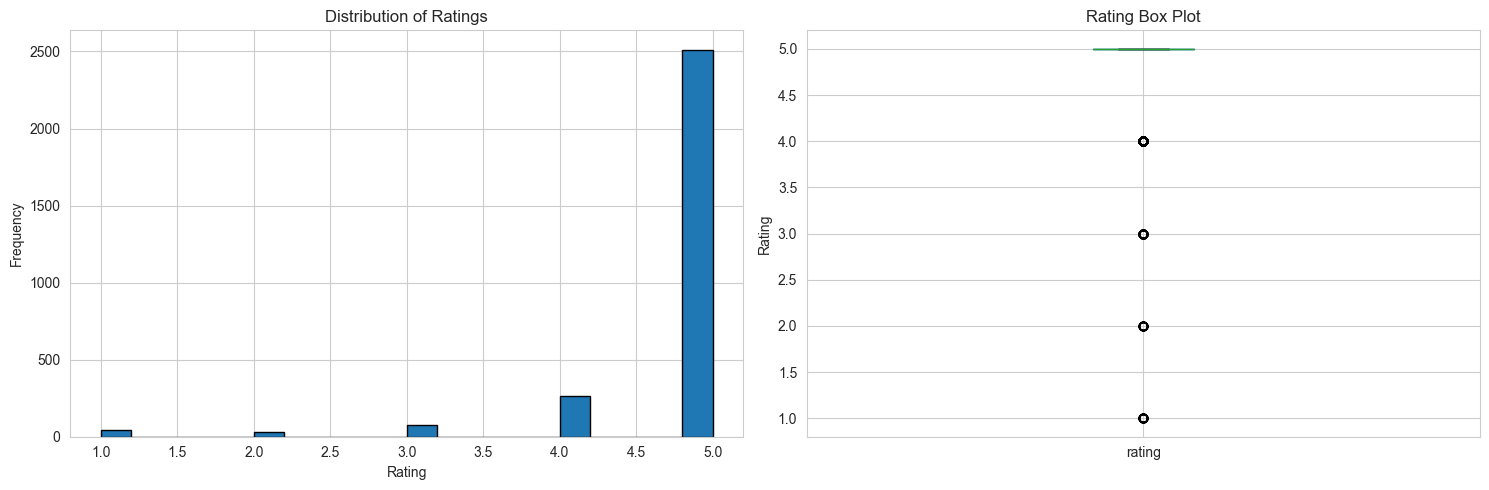

In [14]:
# Rating level distribution
print("Rating  Value Counts:")
df_vc = (df['rating'].value_counts().sort_index().to_frame())
df_vc['pct'] = df_vc['count']/df.shape[0]
print(df_vc)

# Visualize sweet level distribution
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram
df['rating'].hist(bins=20, ax=axes[0], edgecolor='black')
axes[0].set_title('Distribution of Ratings')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frequency')

# Box plot
df.boxplot(column='rating', ax=axes[1])
axes[1].set_title('Rating Box Plot')
axes[1].set_ylabel('Rating')

plt.tight_layout()
plt.show()

In [15]:

print(df['Sentiment Score'].describe())

count    2927.000000
mean        0.752580
std         0.199330
min         0.375587
25%         0.573002
50%         0.757224
75%         0.968215
max         0.990577
Name: Sentiment Score, dtype: float64
